💻 Consumer Electronics Sales Analysis

Step 1 — Import Libraries

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.


Step 2: Upload CSV

In [ ]:
from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[file_name])
)

print("Dataset uploaded successfully!")
print("File name:", file_name)
print("Dataset shape:", df.shape)

Saving consumer_electronics_sales_data.csv to consumer_electronics_sales_data.csv
Dataset uploaded successfully!
File name: consumer_electronics_sales_data.csv
Dataset shape: (9000, 9)


Step 3 : Understand the Dataset

In [ ]:
print("Number of Records:", df.shape[0])
print("Number of Features:", df.shape[1])

print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(i, "-", col)

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFirst 5 Records:")
display(df.head())

Number of Records: 9000
Number of Features: 9

Column Names:
1 - ProductID
2 - ProductCategory
3 - ProductBrand
4 - ProductPrice
5 - CustomerAge
6 - CustomerGender
7 - PurchaseFrequency
8 - CustomerSatisfaction
9 - PurchaseIntent

Data Types:


,Data Type
ProductID,int64
ProductCategory,object
ProductBrand,object
ProductPrice,float64
CustomerAge,int64
CustomerGender,int64
PurchaseFrequency,int64
CustomerSatisfaction,int64
PurchaseIntent,int64



First 5 Records:


,ProductID,ProductCategory,ProductBrand,ProductPrice,CustomerAge,CustomerGender,PurchaseFrequency,CustomerSatisfaction,PurchaseIntent
0,5874,Smartphones,Other Brands,312.949668,18,0,2,1,0
1,5875,Smart Watches,Samsung,980.389404,35,1,7,2,1
2,5876,Tablets,Samsung,2606.718293,63,0,1,5,1
3,5877,Smartphones,Samsung,870.395450,63,1,10,3,1
4,5878,Tablets,Sony,1798.955875,57,0,17,3,0


Step 4 : Data Quality Check

In [ ]:
print("Missing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUnique Values:")
display(df.nunique().to_frame("Unique Values"))

Missing Values:


,Missing Values
ProductID,0
ProductCategory,0
ProductBrand,0
ProductPrice,0
CustomerAge,0
CustomerGender,0
PurchaseFrequency,0
CustomerSatisfaction,0
PurchaseIntent,0



Duplicate Records: 0

Unique Values:


,Unique Values
ProductID,9000
ProductCategory,5
ProductBrand,5
ProductPrice,9000
CustomerAge,52
CustomerGender,2
PurchaseFrequency,19
CustomerSatisfaction,5
PurchaseIntent,2


Step 5 : Statistical Summary

In [ ]:
display(df.describe())

,ProductID,ProductPrice,CustomerAge,CustomerGender,PurchaseFrequency,CustomerSatisfaction,PurchaseIntent
count,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000
mean,10373.500000,1527.429195,43.347000,0.508889,10.054667,2.996000,0.566444
std,2598.220545,829.900898,15.055084,0.499949,5.461328,1.405301,0.495593
min,5874.000000,100.376358,18.000000,0.000000,1.000000,1.000000,0.000000
25%,8123.750000,809.165014,30.000000,0.000000,5.000000,2.000000,0.000000
50%,10373.500000,1513.024577,43.000000,1.000000,10.000000,3.000000,1.000000
75%,12623.250000,2244.415520,56.000000,1.000000,15.000000,4.000000,1.000000
max,14873.000000,2999.852253,69.000000,1.000000,19.000000,5.000000,1.000000


Step 6 : Data Preparation

In [ ]:
numeric_columns = [
    'ProductID',
    'ProductPrice',
    'CustomerAge',
    'CustomerGender',
    'PurchaseFrequency',
    'CustomerSatisfaction',
    'PurchaseIntent'
]

for col in numeric_columns:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col],
        errors='coerce'
    )

# Remove rows with missing analytical values
analysis_df = analysis_df.dropna()

# Create age groups
analysis_df['AgeGroup'] = pd.cut(
    analysis_df['CustomerAge'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '66+'
    ]
)

print("Data preparation completed!")
print("Final dataset shape:", analysis_df.shape)

Data preparation completed!
Final dataset shape: (9000, 11)


Step 7 : Customer Age Distribution

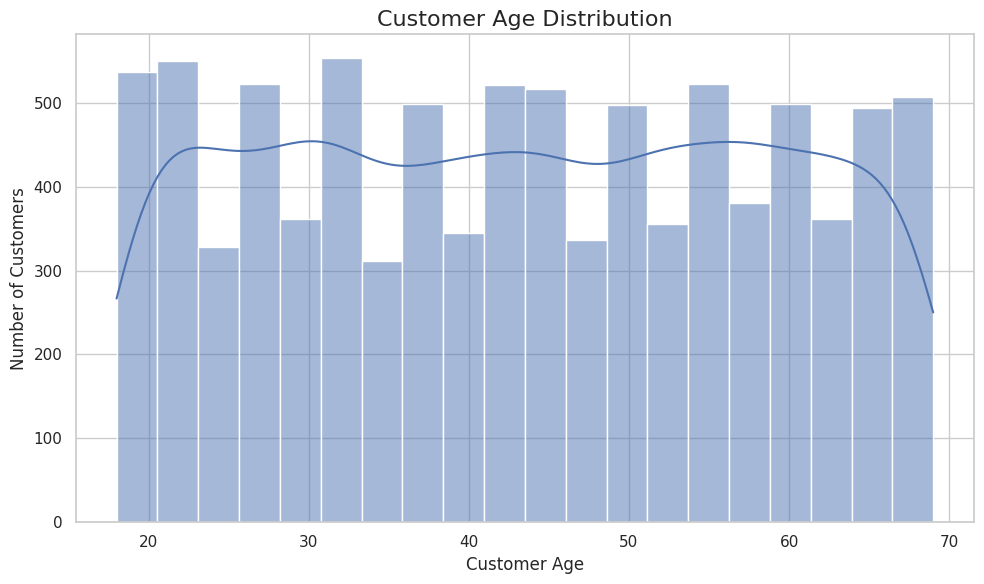

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=analysis_df,
    x='CustomerAge',
    bins=20,
    kde=True
)

plt.title("Customer Age Distribution", fontsize=16)
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Step 8 : Product Category Distribution

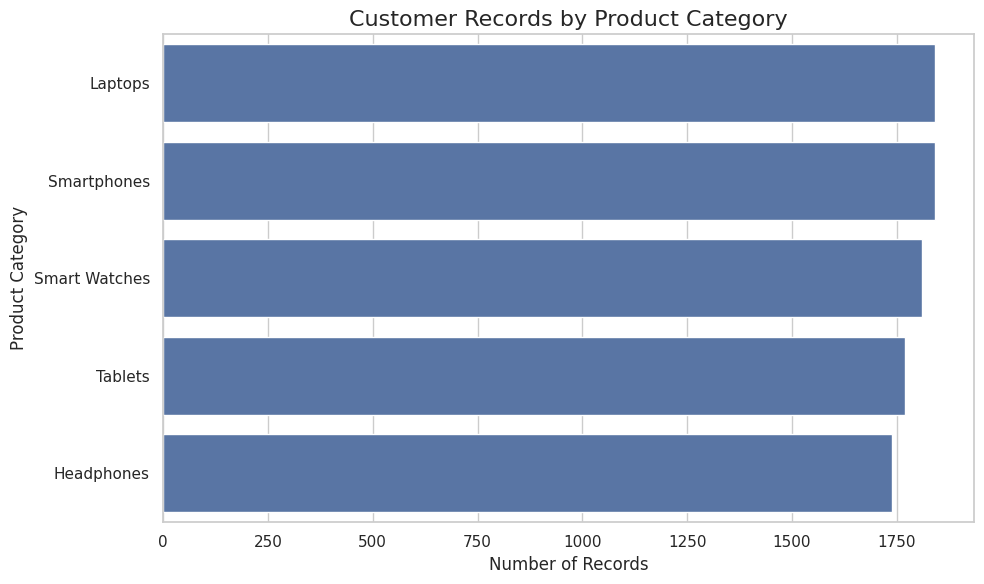

In [ ]:
category_counts = (
    analysis_df['ProductCategory']
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Customer Records by Product Category", fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

Step 9 : Brand Distribution

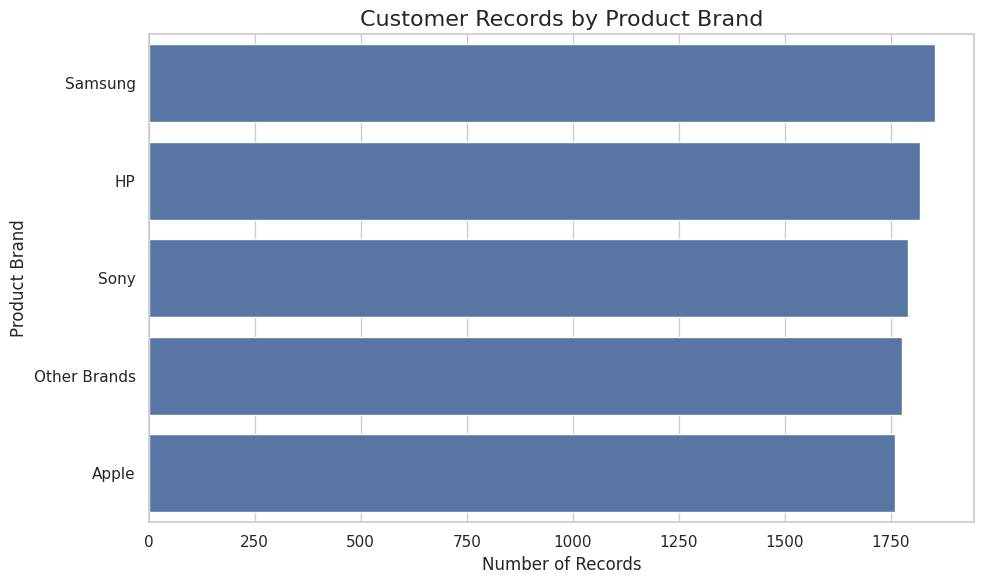

In [ ]:
brand_counts = (
    analysis_df['ProductBrand']
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=brand_counts.values,
    y=brand_counts.index
)

plt.title("Customer Records by Product Brand", fontsize=16)
plt.xlabel("Number of Records")
plt.ylabel("Product Brand")

plt.tight_layout()
plt.show()

Step 10 : Purchase Intent Overview

Purchase Intent Distribution:


,Count
PurchaseIntent,
0,3902
1,5098


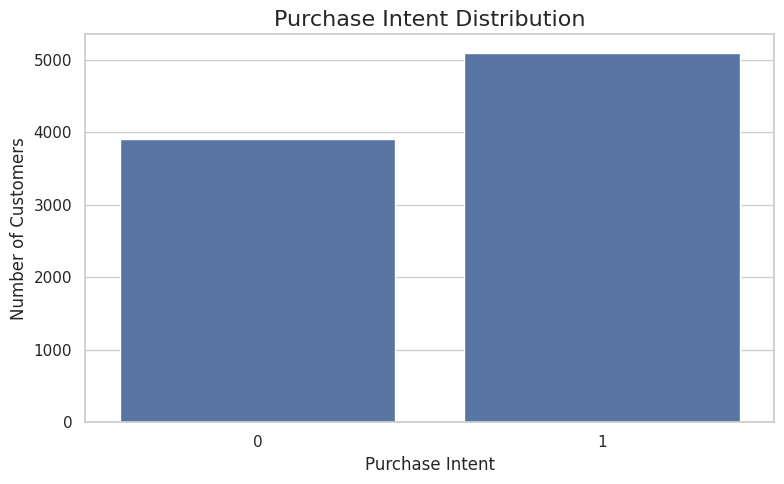

In [ ]:
intent_counts = (
    analysis_df['PurchaseIntent']
    .value_counts()
    .sort_index()
)

print("Purchase Intent Distribution:")
display(intent_counts.to_frame("Count"))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=intent_counts.index.astype(str),
    y=intent_counts.values
)

plt.title("Purchase Intent Distribution", fontsize=16)
plt.xlabel("Purchase Intent")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Step 11 : Purchase Intent by Product Category

,ProductCategory,Purchase Intent %
0,Smartphones,58.28
1,Smart Watches,58.12
2,Tablets,56.08
3,Headphones,55.98
4,Laptops,54.72


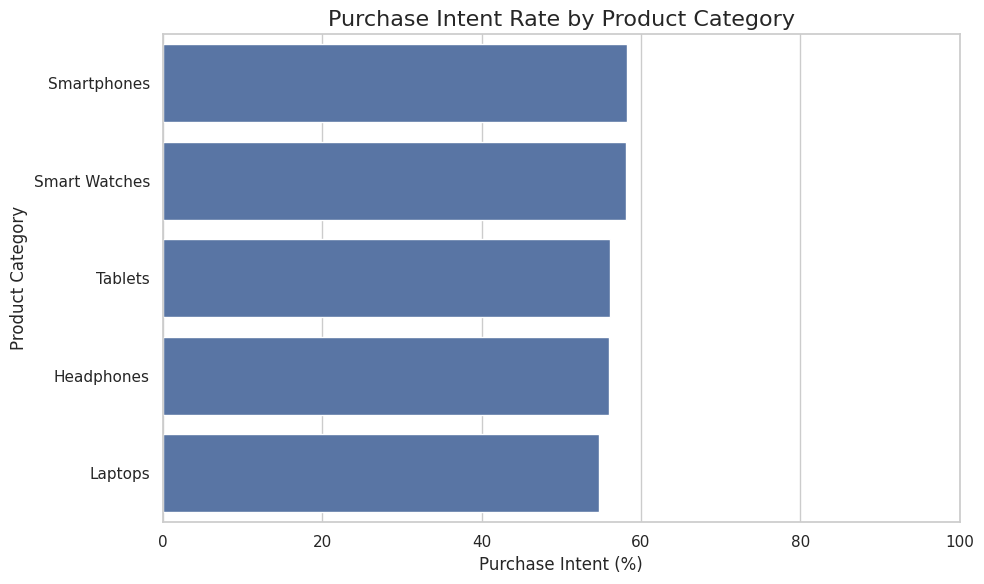

In [ ]:
category_intent = (
    analysis_df
    .groupby('ProductCategory')['PurchaseIntent']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

category_intent['Purchase Intent %'] = (
    category_intent['PurchaseIntent'] * 100
)

display(
    category_intent[
        ['ProductCategory', 'Purchase Intent %']
    ].round(2)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_intent,
    x='Purchase Intent %',
    y='ProductCategory'
)

plt.title(
    "Purchase Intent Rate by Product Category",
    fontsize=16
)

plt.xlabel("Purchase Intent (%)")
plt.ylabel("Product Category")

plt.xlim(0, 100)

plt.tight_layout()
plt.show()

Step 12 : Purchase Intent by Brand

,ProductBrand,Purchase Intent %
0,Apple,58.69
1,HP,57.36
2,Other Brands,56.64
3,Sony,56.20
4,Samsung,54.42


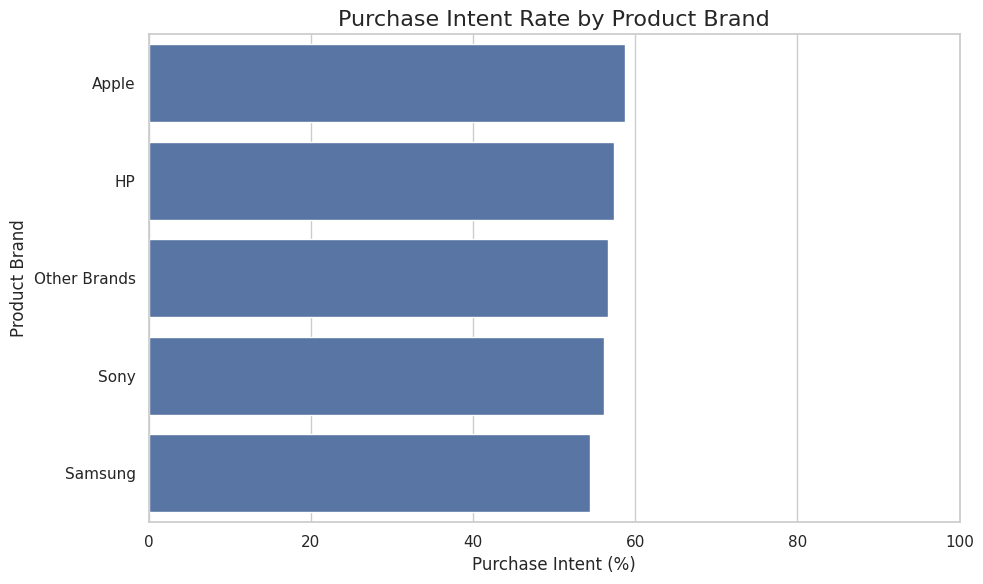

In [ ]:
brand_intent = (
    analysis_df
    .groupby('ProductBrand')['PurchaseIntent']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

brand_intent['Purchase Intent %'] = (
    brand_intent['PurchaseIntent'] * 100
)

display(
    brand_intent[
        ['ProductBrand', 'Purchase Intent %']
    ].round(2)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=brand_intent,
    x='Purchase Intent %',
    y='ProductBrand'
)

plt.title(
    "Purchase Intent Rate by Product Brand",
    fontsize=16
)

plt.xlabel("Purchase Intent (%)")
plt.ylabel("Product Brand")

plt.xlim(0, 100)

plt.tight_layout()
plt.show()

Step 13 : Customer Satisfaction vs Purchase Intent

,CustomerSatisfaction,Purchase Intent %
0,1,38.54
1,2,38.92
2,3,37.66
3,4,84.48
4,5,84.59


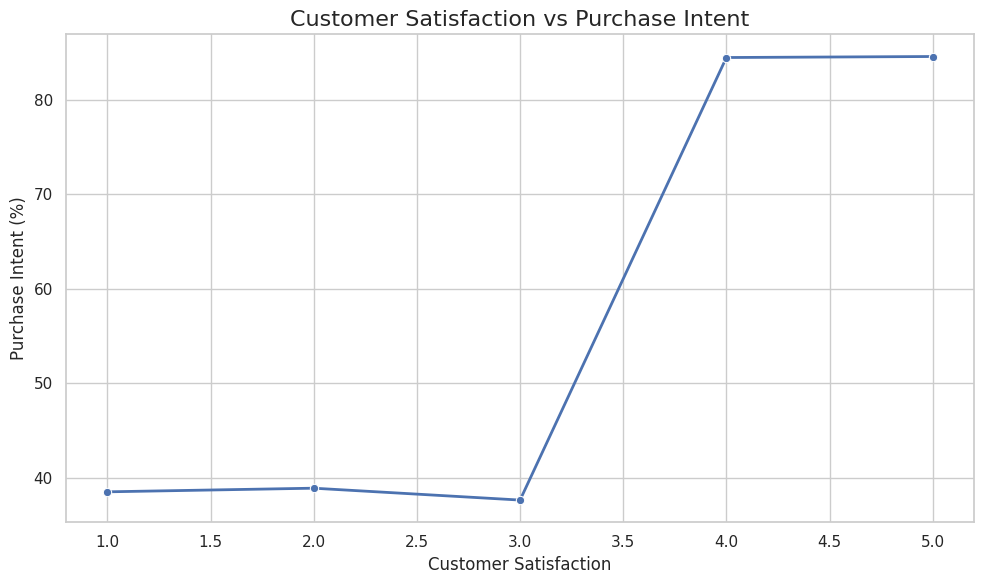

In [ ]:
satisfaction_intent = (
    analysis_df
    .groupby('CustomerSatisfaction')['PurchaseIntent']
    .mean()
    .reset_index()
)

satisfaction_intent['Purchase Intent %'] = (
    satisfaction_intent['PurchaseIntent'] * 100
)

display(
    satisfaction_intent[
        ['CustomerSatisfaction', 'Purchase Intent %']
    ].round(2)
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=satisfaction_intent,
    x='CustomerSatisfaction',
    y='Purchase Intent %',
    marker='o',
    linewidth=2
)

plt.title(
    "Customer Satisfaction vs Purchase Intent",
    fontsize=16
)

plt.xlabel("Customer Satisfaction")
plt.ylabel("Purchase Intent (%)")

plt.tight_layout()
plt.show()

Step 14 : Purchase Frequency vs Purchase Intent

,PurchaseIntent,count,mean,median
0,0,3902,10.063813,10.0
1,1,5098,10.047666,10.0


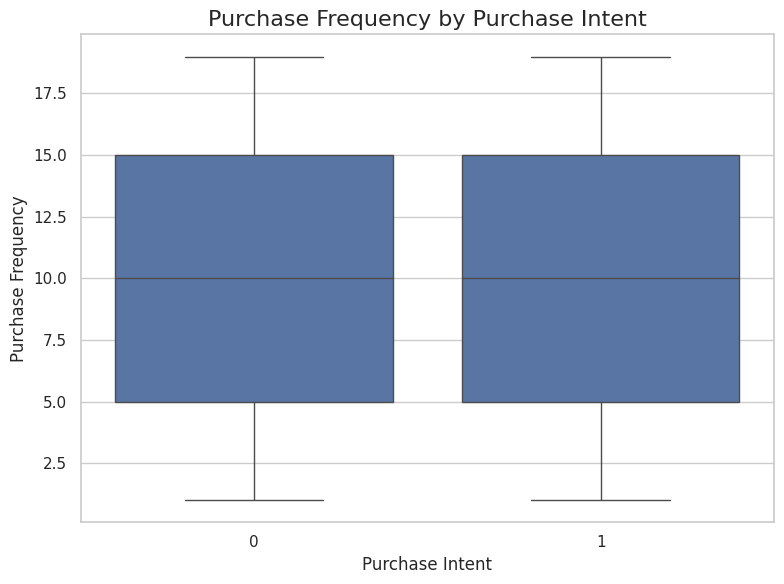

In [ ]:
frequency_intent = (
    analysis_df
    .groupby('PurchaseIntent')['PurchaseFrequency']
    .agg(['count', 'mean', 'median'])
    .reset_index()
)

display(frequency_intent)

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=analysis_df,
    x='PurchaseIntent',
    y='PurchaseFrequency'
)

plt.title(
    "Purchase Frequency by Purchase Intent",
    fontsize=16
)

plt.xlabel("Purchase Intent")
plt.ylabel("Purchase Frequency")

plt.tight_layout()
plt.show()

Step 15 : Product Price vs Purchase Intent

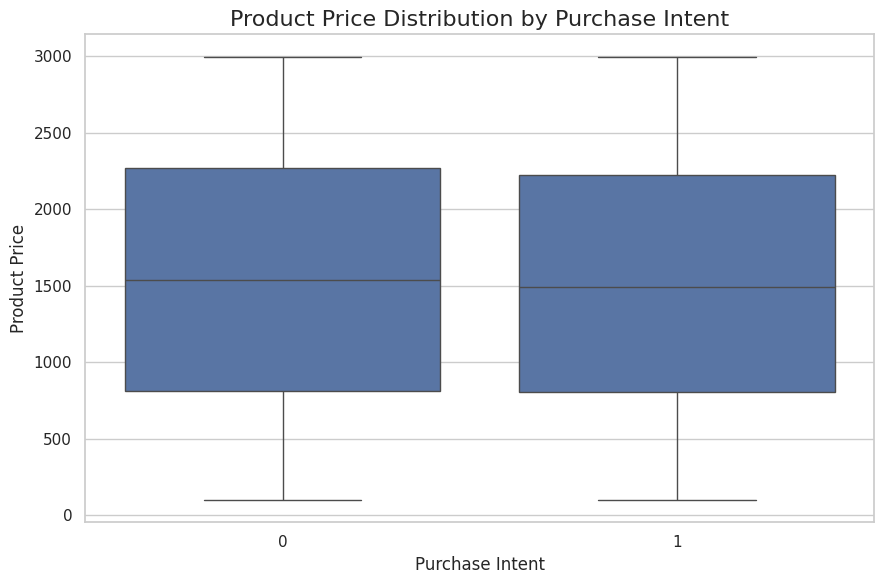

In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=analysis_df,
    x='PurchaseIntent',
    y='ProductPrice'
)

plt.title(
    "Product Price Distribution by Purchase Intent",
    fontsize=16
)

plt.xlabel("Purchase Intent")
plt.ylabel("Product Price")

plt.tight_layout()
plt.show()

Step 16 : Age Group vs Purchase Intent

,AgeGroup,Purchase Intent %
0,18-25,23.11
1,26-35,45.74
2,36-45,69.01
3,46-55,66.14
4,56-65,70.35
5,66+,64.45


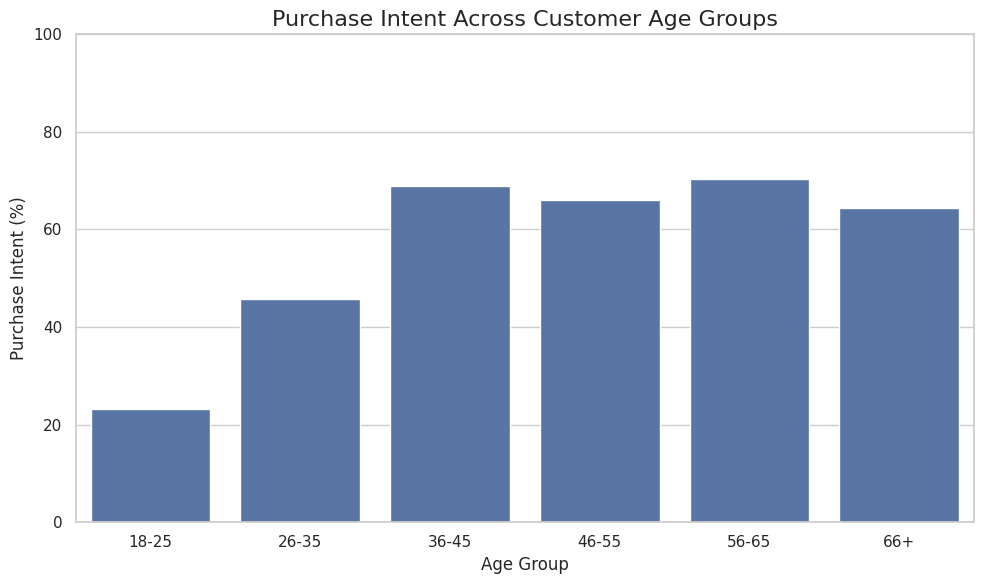

In [ ]:
age_intent = (
    analysis_df
    .groupby('AgeGroup', observed=True)['PurchaseIntent']
    .mean()
    .reset_index()
)

age_intent['Purchase Intent %'] = (
    age_intent['PurchaseIntent'] * 100
)

display(
    age_intent[
        ['AgeGroup', 'Purchase Intent %']
    ].round(2)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_intent,
    x='AgeGroup',
    y='Purchase Intent %'
)

plt.title(
    "Purchase Intent Across Customer Age Groups",
    fontsize=16
)

plt.xlabel("Age Group")
plt.ylabel("Purchase Intent (%)")

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

Step 17 : Category and Brand Comparison

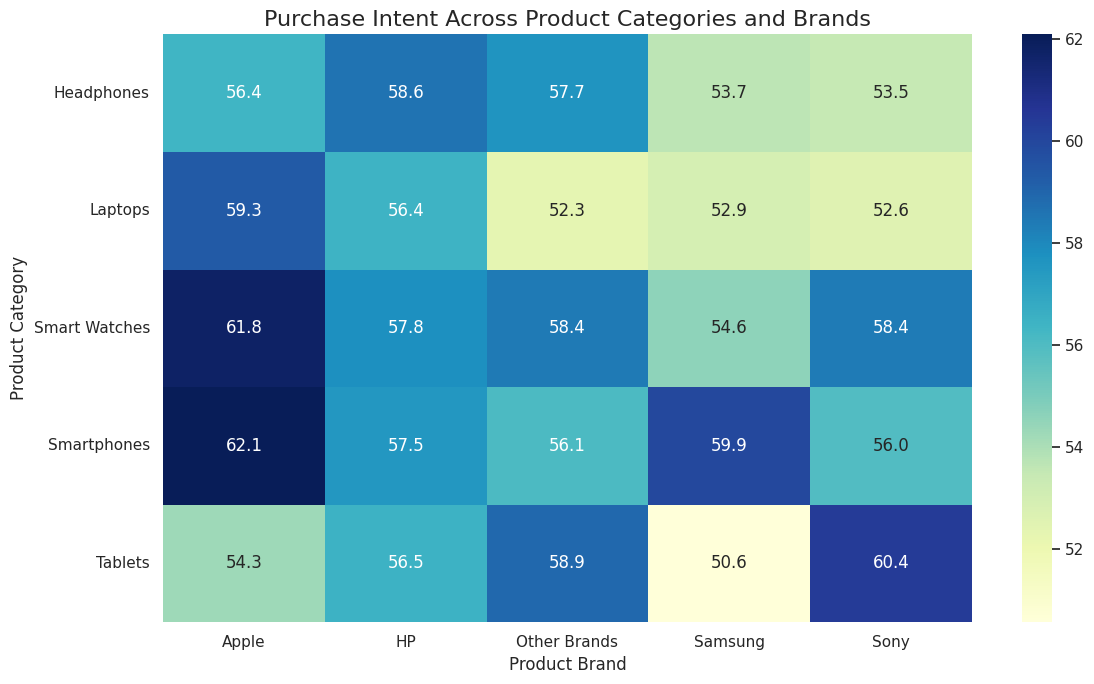

In [ ]:
category_brand = pd.pivot_table(
    analysis_df,
    values='PurchaseIntent',
    index='ProductCategory',
    columns='ProductBrand',
    aggfunc='mean'
) * 100

plt.figure(figsize=(12, 7))

sns.heatmap(
    category_brand,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title(
    "Purchase Intent Across Product Categories and Brands",
    fontsize=16
)

plt.xlabel("Product Brand")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

Step 18 : Correlation Analysis

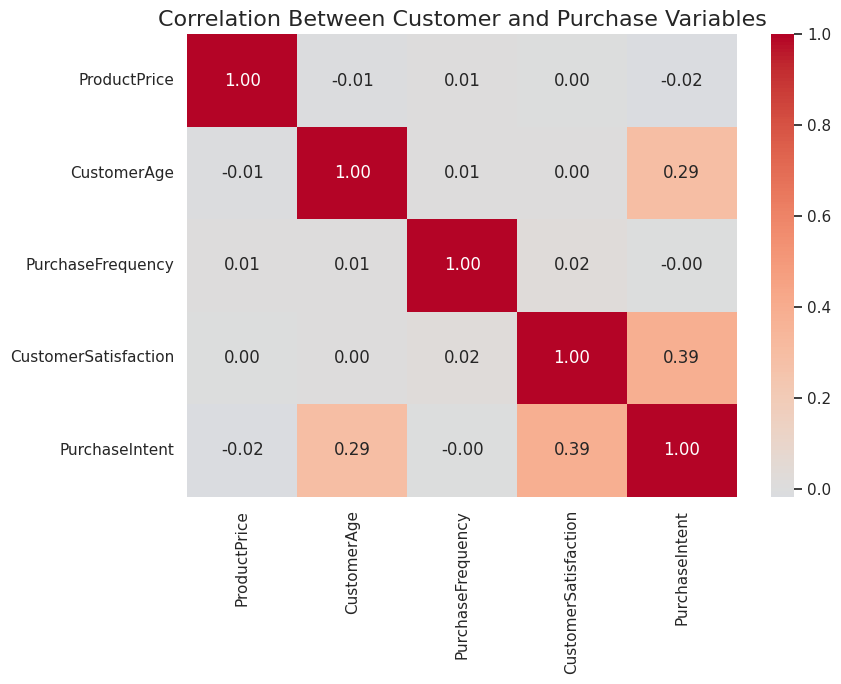

In [ ]:
correlation_columns = [
    'ProductPrice',
    'CustomerAge',
    'PurchaseFrequency',
    'CustomerSatisfaction',
    'PurchaseIntent'
]

correlation_matrix = analysis_df[
    correlation_columns
].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Between Customer and Purchase Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

Step 19 : Statistical Test: Satisfaction vs Purchase Intent

In [ ]:
contingency_table = pd.crosstab(
    analysis_df['CustomerSatisfaction'],
    analysis_df['PurchaseIntent']
)

print("Contingency Table:")
display(contingency_table)

# Reference chi2_contingency from the imported stats module
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", round(chi2, 4))
print("p-value:", p_value)

if p_value < 0.05:
    print(
        "\nResult: There is a statistically significant "
        "association between Customer Satisfaction and Purchase Intent."
    )
else:
    print(
        "\nResult: No statistically significant association "
        "was detected between Customer Satisfaction and Purchase Intent."
    )

Contingency Table:


PurchaseIntent,0,1
CustomerSatisfaction,,
1,1091,684
2,1108,706
3,1152,696
4,279,1519
5,272,1493


Chi-square statistic: 1868.8391
p-value: 0.0

Result: There is a statistically significant association between Customer Satisfaction and Purchase Intent.


Step 20 : Key Data-Driven Findings

In [ ]:
overall_intent = analysis_df['PurchaseIntent'].mean() * 100

best_category = category_intent.iloc[0]

best_brand = brand_intent.iloc[0]

highest_satisfaction = satisfaction_intent.iloc[-1]

print("KEY DATA-DRIVEN FINDINGS")
print("=" * 60)

print(
    f"1. Overall purchase intent: {overall_intent:.2f}%"
)

print(
    f"2. Highest purchase-intent category: "
    f"{best_category['ProductCategory']} "
    f"({best_category['Purchase Intent %']:.2f}%)"
)

print(
    f"3. Highest purchase-intent brand: "
    f"{best_brand['ProductBrand']} "
    f"({best_brand['Purchase Intent %']:.2f}%)"
)

print(
    f"4. Highest satisfaction level: "
    f"{int(highest_satisfaction['CustomerSatisfaction'])} "
    f"with purchase intent of "
    f"{highest_satisfaction['Purchase Intent %']:.2f}%"
)

print(
    "5. Customer satisfaction shows a strong relationship "
    "with purchase intent in the dataset."
)

KEY DATA-DRIVEN FINDINGS
1. Overall purchase intent: 56.64%
2. Highest purchase-intent category: Smartphones (58.28%)
3. Highest purchase-intent brand: Apple (58.69%)
4. Highest satisfaction level: 5 with purchase intent of 84.59%
5. Customer satisfaction shows a strong relationship with purchase intent in the dataset.


Step 21 : Final Business Insights

In [ ]:
print("""
FINAL BUSINESS INSIGHTS

1. Purchase intent varies across consumer electronics categories,
   indicating differences in customer interest across product types.

2. Purchase intent also varies across brands, providing useful
   information for brand-level customer analysis.

3. Customer satisfaction is strongly associated with purchase intent,
   making satisfaction an important customer-behavior indicator.

4. Purchase frequency provides additional information about customer
   purchasing behavior and can be compared with future purchase intent.

5. Price distribution can be examined to understand whether purchase
   interest differs across different product price levels.

6. Age-group analysis helps identify customer segments with relatively
   higher or lower purchase intent.

7. Category-brand analysis provides a more detailed view of product
   combinations associated with customer interest.

8. Statistical testing helps distinguish observed patterns from
   differences that may be statistically meaningful.

Overall, the analysis converts customer and product-level data into
actionable insights that can support customer segmentation,
product strategy, and marketing decisions.
""")


FINAL BUSINESS INSIGHTS

1. Purchase intent varies across consumer electronics categories,
   indicating differences in customer interest across product types.

2. Purchase intent also varies across brands, providing useful
   information for brand-level customer analysis.

3. Customer satisfaction is strongly associated with purchase intent,
   making satisfaction an important customer-behavior indicator.

4. Purchase frequency provides additional information about customer
   purchasing behavior and can be compared with future purchase intent.

5. Price distribution can be examined to understand whether purchase
   interest differs across different product price levels.

6. Age-group analysis helps identify customer segments with relatively
   higher or lower purchase intent.

7. Category-brand analysis provides a more detailed view of product
   combinations associated with customer interest.

8. Statistical testing helps distinguish observed patterns from
   differences that may b